**Тема:**

Предсказание оттока клиентов банка

**Цель работы:**

Построить baseline-решение для задачи предсказания оттока клиентов банка, затем обучить более сложную ансамблевую модель с подбором гиперпараметров и проинтерпретировать полученные результаты.

**Бизнес-постановка:**

Банку важно заранее выявлять клиентов, склонных к уходу, чтобы вовремя запускать retention-механики.

**ML-постановка:**

Задача бинарной классификации: 1 - клиент уйдет, 0 - клиент останется

**Метрики качества:**

Целевая метрика - Recall для класса оттока, т.к. Наиболее критична ошибка типа False Negative: если модель не распознает клиента, склонного к уходу, банк потеряет возможность своевременно его удержать.

Дополнительная метрика - f1-score, т.к она позволяет оценить баланс между полнотой и точностью.



In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    recall_score,
    f1_score,
    precision_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

RANDOM_STATE = 52

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

**Загрусзка данных**

Используется датасет с информацией о клиентах банка и целевой переменной **churn**, которая показывает, ушел клиент или нет.

Random_state = 52, чтобы результаты были воспроизводимы.

In [23]:
df = pd.read_csv("Bank Customer Churn Prediction.csv")

print("Размер датасета:", df.shape)
display(df.head())
display(df.info())
display(df.isnull().sum())
display(df.duplicated().sum())

Размер датасета: (10000, 12)


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


None

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


np.int64(0)

**Подготовка данных***

Из набора данных удаляется **customer_id**, так как он не несет полезной информации для модели.

Далее датасет разбивается на обучающую и тестовую выборки. Используется стратифицированное разбиение, чтобы сохранить исходное соотношение классов в train и test.

In [24]:
df = df.drop(columns=["customer_id"]).copy()

target_col = "churn"

X = df.drop(columns=[target_col])
y = df[target_col]

categorical_features = ["country", "gender"]
numeric_features = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "products_number",
    "credit_card",
    "active_member",
    "estimated_salary",
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nДоля классов в train:")
display(y_train.value_counts(normalize=True).round(3))

print("\nДоля классов в test:")
display(y_test.value_counts(normalize=True).round(3))

Train shape: (8000, 10)
Test shape: (2000, 10)

Доля классов в train:


,proportion
churn,
0,0.796
1,0.204



Доля классов в test:


,proportion
churn,
0,0.796
1,0.204


**Предобработка признаков**

Для числовых признаков используется:
- заполнение пропусков медианой,
- стандартизация.

Для категориальных признаков используется:
- заполнение пропусков наиболее частым значением,
- one-hot encoding.

Такой подход важен для линейных моделей, поскольку они чувствительны к масштабу признаков и не умеют работать со строковыми категориями напрямую.

In [25]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

**Вспомогательная функция оценки моделей**

Ниже определяется функция, которая:
- обучает модель;
- считает метрики на train и test;
- выводит classification report;
- строит confusion matrix.

Это позволяет единообразно сравнивать baseline и более сложные модели.

In [26]:
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name="model"):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    metrics = {
        "model": model_name,
        "train_recall": recall_score(y_train, train_pred),
        "test_recall": recall_score(y_test, test_pred),
        "train_f1": f1_score(y_train, train_pred),
        "test_f1": f1_score(y_test, test_pred),
        "train_precision": precision_score(y_train, train_pred),
        "test_precision": precision_score(y_test, test_pred),
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred),
    }

    print(f"===== {model_name} =====")
    display(pd.DataFrame([metrics]))

    print("\nClassification report:")
    print(classification_report(y_test, test_pred))

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, test_pred, ax=ax)
    plt.title(f"Confusion matrix: {model_name}")
    plt.show()

    return metrics

**Константный baseline**

В качестве самого простого baseline используется **DummyClassifier**, который всегда предсказывает наиболее частый класс.

Этот шаг нужен, чтобы проверить, действительно ли более сложные модели извлекают полезный сигнал из данных, а не просто повторяют распределение классов.

===== DummyClassifier_most_frequent =====


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,model,train_recall,test_recall,train_f1,test_f1,train_precision,test_precision,train_accuracy,test_accuracy
0,DummyClassifier_most_frequent,0.0,0.0,0.0,0.0,0.0,0.0,0.79625,0.7965



Classification report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1593
           1       0.00      0.00      0.00       407

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.63      0.80      0.71      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


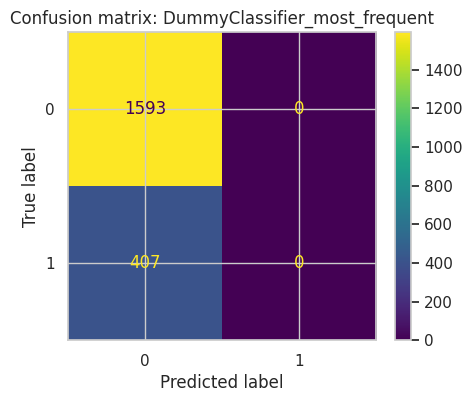

In [27]:
dummy_clf = DummyClassifier(strategy="most_frequent")

dummy_metrics = evaluate_model(
    dummy_clf,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="DummyClassifier_most_frequent",
)

**Baseline-модель**

В качестве baseline-модели выбрана **Logistic Regression**.

Причины выбора:
- это простая и интерпретируемая модель,
- она часто используется как сильный baseline в задачах бинарной классификации,
- для нее понятны требования к предобработке данных.

===== LogisticRegression_baseline =====


,model,train_recall,test_recall,train_f1,test_f1,train_precision,test_precision,train_accuracy,test_accuracy
0,LogisticRegression_baseline,0.212883,0.181818,0.315025,0.276636,0.605585,0.578125,0.811375,0.8065



Classification report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.58      0.18      0.28       407

    accuracy                           0.81      2000
   macro avg       0.70      0.57      0.58      2000
weighted avg       0.77      0.81      0.76      2000



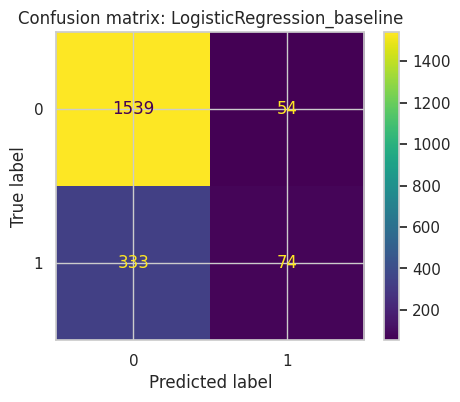

In [28]:
logreg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
    ]
)

logreg_metrics = evaluate_model(
    logreg_pipeline,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="LogisticRegression_baseline",
)

**Сравнение baseline-подходов**

Сравним качество константного baseline и логистической регрессии на тестовой выборке.

In [29]:
baseline_results = pd.DataFrame([dummy_metrics, logreg_metrics])
display(baseline_results.sort_values(by="test_recall", ascending=False))

,model,train_recall,test_recall,train_f1,test_f1,train_precision,test_precision,train_accuracy,test_accuracy
1,LogisticRegression_baseline,0.212883,0.181818,0.315025,0.276636,0.605585,0.578125,0.811375,0.8065
0,DummyClassifier_most_frequent,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.796250,0.7965


**Более сложная модель**

В качестве более сложной модели выбран **Random Forest**.

Причины выбора:
- это ансамблевая модель, которая умеет учитывать нелинейные зависимости;
- она хорошо работает на табличных данных;
- модель менее чувствительна к выбросам и масштабу признаков, чем линейные методы;
- Random Forest удобно интерпретировать через permutation importance и SHAP.

Подбор гиперпараметров будет выполняться с помощью **RandomizedSearchCV** на стратифицированной кросс-валидации. В качестве метрики для оптимизации используется **recall**.

In [30]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    ]
)

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 5, 7, 10, 15, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="recall",
    cv=cv,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_search.fit(X_train, y_train)

print("Лучшие гиперпараметры:")
display(rf_search.best_params_)

print("Лучший CV recall:")
print(rf_search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Лучшие гиперпараметры:


{'model__n_estimators': 100,
 'model__min_samples_split': 20,
 'model__min_samples_leaf': 2,
 'model__max_features': None,
 'model__max_depth': 7,
 'model__class_weight': 'balanced'}

Лучший CV recall:
0.7257668711656441


**Оценка лучшей ансамблевой модели**

После подбора гиперпараметров оценивается лучшая найденная модель на отложенной тестовой выборке.

===== RandomForest_tuned =====


,model,train_recall,test_recall,train_f1,test_f1,train_precision,test_precision,train_accuracy,test_accuracy
0,RandomForest_tuned,0.802454,0.742015,0.650584,0.603397,0.547051,0.508418,0.824375,0.8015



Classification report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      1593
           1       0.51      0.74      0.60       407

    accuracy                           0.80      2000
   macro avg       0.72      0.78      0.74      2000
weighted avg       0.84      0.80      0.81      2000



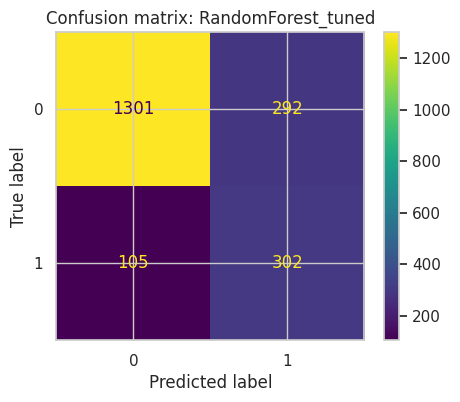

In [31]:
best_rf_model = rf_search.best_estimator_

rf_metrics = evaluate_model(
    best_rf_model,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="RandomForest_tuned",
)

**Сравнение всех моделей**

Сравним три подхода:
- константный baseline,
- логистическую регрессию,
- ансамблевую модель Random Forest после подбора гиперпараметров.

In [32]:
all_results = pd.DataFrame([dummy_metrics, logreg_metrics, rf_metrics])
display(all_results.sort_values(by="test_recall", ascending=False))

,model,train_recall,test_recall,train_f1,test_f1,train_precision,test_precision,train_accuracy,test_accuracy
2,RandomForest_tuned,0.802454,0.742015,0.650584,0.603397,0.547051,0.508418,0.824375,0.8015
1,LogisticRegression_baseline,0.212883,0.181818,0.315025,0.276636,0.605585,0.578125,0.811375,0.8065
0,DummyClassifier_most_frequent,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.796250,0.7965


**Глобальная интерпретация модели**

Для глобальной интерпретации используется **permutation importance**.

Идея метода: если случайно перемешать значения важного признака, качество модели должно заметно ухудшиться. Чем сильнее падает recall, тем важнее признак.

,feature,importance_mean,importance_std
3,age,0.172482,0.015609
6,products_number,0.161671,0.016142
5,balance,0.107125,0.012871
1,country,0.078870,0.008957
8,active_member,0.019902,0.006542
2,gender,0.008354,0.004557
7,credit_card,0.001229,0.001229
4,tenure,0.000983,0.004688
0,credit_score,0.000737,0.005715
9,estimated_salary,-0.000246,0.004720


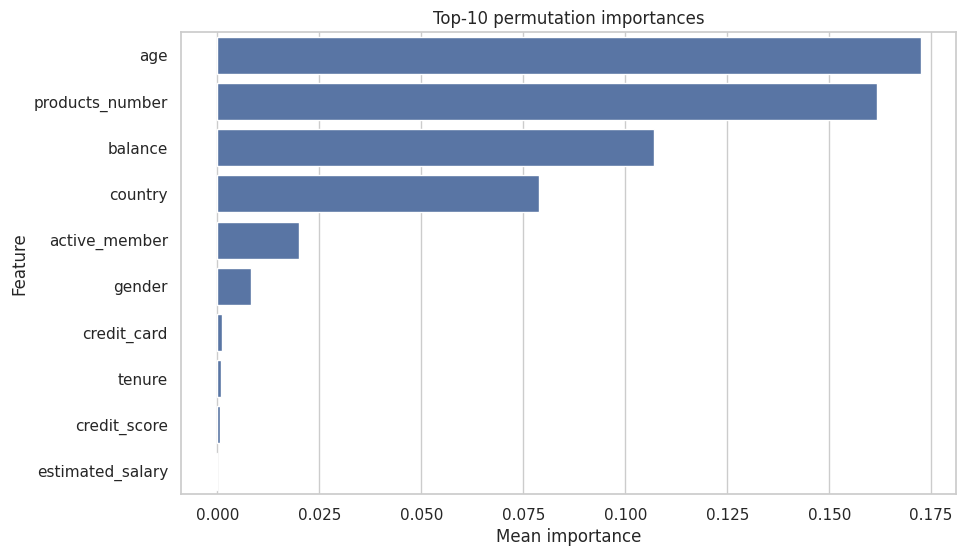

In [33]:
perm_result = permutation_importance(
    best_rf_model,
    X_test,
    y_test,
    scoring="recall",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm_importance_df = pd.DataFrame(
    {
        "feature": X_test.columns,
        "importance_mean": perm_result.importances_mean,
        "importance_std": perm_result.importances_std,
    }
).sort_values(by="importance_mean", ascending=False)

display(perm_importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=perm_importance_df.head(10),
    x="importance_mean",
    y="feature",
)
plt.title("Top-10 permutation importances")
plt.xlabel("Mean importance")
plt.ylabel("Feature")
plt.show()

**Подготовка данных для SHAP**

Для SHAP нужно отдельно взять:
- обученный препроцессор;
- обученную модель Random Forest;
- преобразованные данные после one-hot encoding.

Это позволит корректно интерпретировать вклад признаков в предсказание.

In [34]:
import shap
fitted_preprocessor = best_rf_model.named_steps["preprocessor"]
fitted_rf = best_rf_model.named_steps["model"]

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index,
)

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index,
)

print("Размер преобразованной test-выборки:", X_test_transformed_df.shape)
display(X_test_transformed_df.head())

Размер преобразованной test-выборки: (2000, 13)


,num__credit_score,num__age,num__tenure,num__balance,num__products_number,num__credit_card,num__active_member,num__estimated_salary,cat__country_France,cat__country_Germany,cat__country_Spain,cat__gender_Female,cat__gender_Male
6270,0.466950,-1.425134,1.366603,-1.230821,-0.913296,-1.544979,-1.024295,-1.553047,0.0,0.0,1.0,0.0,1.0
6925,0.084428,-0.951946,1.366603,0.094048,-0.913296,0.647258,0.976281,-0.284573,0.0,1.0,0.0,0.0,1.0
6682,-0.112003,-0.951946,-0.014327,1.920111,0.805445,0.647258,-1.024295,0.708045,0.0,0.0,1.0,0.0,1.0
9097,0.797780,0.372978,0.676138,-1.230821,0.805445,0.647258,-1.024295,-1.048425,1.0,0.0,0.0,0.0,1.0
8780,1.748917,-0.005572,1.366603,0.548159,-0.913296,0.647258,-1.024295,-1.451106,0.0,1.0,0.0,0.0,1.0


**Глобальная интерпретация через SHAP**

SHAP summary plot показывает:
- какие признаки чаще всего влияют на предсказание,
- в какую сторону они сдвигают вероятность класса **churn = 1**.

Форма shap_values_class_1: (2000, 13)
Форма X_test_transformed_df: (2000, 13)


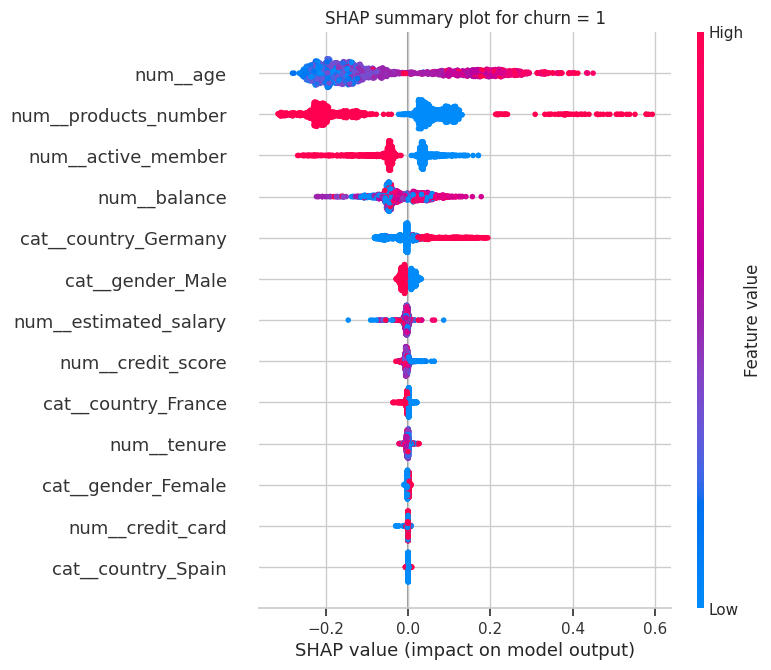

In [37]:
explainer = shap.TreeExplainer(fitted_rf)
shap_values = explainer.shap_values(X_test_transformed_df)

if isinstance(shap_values, list):
    shap_values_class_1 = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_values_class_1 = shap_values[:, :, 1]
else:
    shap_values_class_1 = shap_values

print("Форма shap_values_class_1:", np.array(shap_values_class_1).shape)
print("Форма X_test_transformed_df:", X_test_transformed_df.shape)

shap.summary_plot(shap_values_class_1, X_test_transformed_df, show=False)
plt.title("SHAP summary plot for churn = 1")
plt.show()

**Локальная интерпретация**

Теперь рассмотрим предсказание для одного конкретного клиента.

Для этого используется SHAP waterfall plot, который показывает:
- базовое значение модели,
- признаки, увеличивающие вероятность оттока,
- признаки, уменьшающие вероятность оттока.

Исходный объект:


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
6270,696,Spain,Male,24,9,0.0,1,0,0,10883.52


Истинный класс: 0
Предсказанный класс: 0
Предсказанная вероятность churn: 0.4540325591704


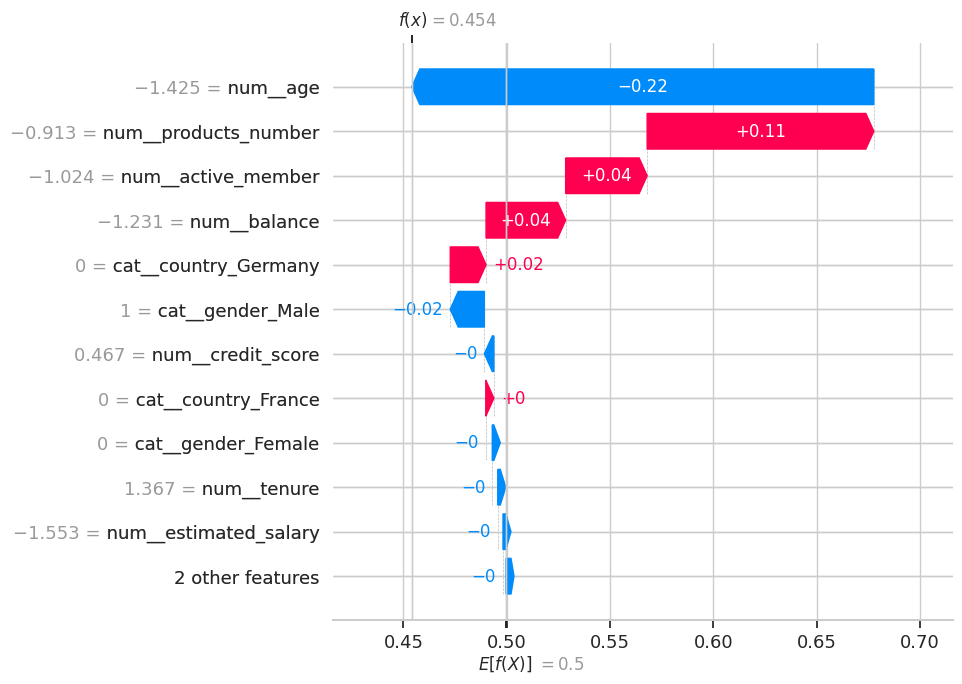

In [36]:
row_idx = X_test_transformed_df.index[0]
sample = X_test_transformed_df.loc[[row_idx]]

print("Исходный объект:")
display(X_test.loc[[row_idx]])

print("Истинный класс:", y_test.loc[row_idx])
print("Предсказанный класс:", best_rf_model.predict(X_test.loc[[row_idx]])[0])
print("Предсказанная вероятность churn:", best_rf_model.predict_proba(X_test.loc[[row_idx]])[0, 1])

sample_position = list(X_test_transformed_df.index).index(row_idx)

# Для разных версий shap обрабатываем несколько возможных форматов
if isinstance(shap_values, list):
    # старый формат: список по классам
    sample_values = shap_values[1][sample_position]
    sample_base_value = explainer.expected_value[1]
elif len(shap_values.shape) == 3:
    # новый формат: (n_objects, n_features, n_classes)
    sample_values = shap_values[sample_position, :, 1]
    sample_base_value = explainer.expected_value[1]
else:
    # формат: (n_objects, n_features)
    sample_values = shap_values[sample_position]
    sample_base_value = explainer.expected_value

shap.plots.waterfall(
    shap.Explanation(
        values=sample_values,
        base_values=sample_base_value,
        data=sample.values[0],
        feature_names=sample.columns.tolist(),
    ),
    max_display=12,
)

**Интерпретация результатов**

**Глобальная интерпретация**

Для глобальной интерпретации лучшей модели использовались `permutation importance` и `SHAP summary plot`. По результатам анализа наиболее значимыми признаками оказались `age`, `products_number`, `active_member`, `balance`, а также признак `country_Germany`. Также заметное, хотя и менее сильное, влияние оказывали `estimated_salary` и `credit_score`.

Это означает, что модель в наибольшей степени опирается на возраст клиента, количество используемых банковских продуктов, уровень активности, баланс счета и страну клиента. Такая интерпретация выглядит правдоподобно с точки зрения предметной области, поскольку вовлеченность клиента в банковские сервисы и его поведение действительно могут быть связаны с вероятностью ухода.

**Локальная интерпретация**

Для локальной интерпретации был использован `SHAP waterfall plot` для отдельного клиента из тестовой выборки. Для выбранного объекта модель предсказала класс `0` при вероятности оттока `0.454`, что соответствует истинному классу.

Waterfall plot показал, что наибольший вклад в снижение вероятности оттока внес признак `age`. В сторону увеличения вероятности оттока работали `products_number`, `active_member`, `balance` и в меньшей степени некоторые категориальные признаки, связанные со страной клиента. Это показывает, что итоговое решение модели формируется как результат совместного влияния нескольких факторов, часть из которых повышает риск ухода, а часть — снижает его.

**Мнение**

Полученная интерпретация выглядит адекватной. Модель опирается на признаки, действительно связанные с вовлеченностью клиента и его поведением в банке. Тот факт, что среди наиболее важных факторов оказались `age`, `active_member`, `products_number` и `balance`, хорошо согласуется с логикой churn-анализа. Это повышает доверие к модели и позволяет считать ее предсказания содержательно осмысленными.

**Вывод**

В рамках задания были построены и сравнены несколько моделей для предсказания оттока клиентов банка.

Сначала был рассчитан константный baseline с помощью `DummyClassifier`, затем обучена baseline-модель `LogisticRegression` с корректной предобработкой признаков. После этого была обучена более сложная ансамблевая модель `RandomForestClassifier`, для которой был выполнен подбор гиперпараметров с помощью `RandomizedSearchCV` на стратифицированной кросс-валидации.

Лучшей оказалась модель `RandomForestClassifier` со следующими гиперпараметрами: `n_estimators = 100`, `max_depth = 7`, `min_samples_split = 20`, `min_samples_leaf = 2`, `max_features = None`, `class_weight = 'balanced'`. Лучшее среднее значение `Recall` на кросс-валидации составило `0.726`.

На тестовой выборке ансамблевая модель показала:
- `Recall = 0.742`
- `F1-score = 0.603`
- `Precision = 0.508`
- `Accuracy = 0.802`

Для сравнения, baseline-модель `LogisticRegression` показала значительно более низкое качество:
- `Recall = 0.182`
- `F1-score = 0.277`

Следовательно, использование ансамблевой модели существенно улучшило решение основной бизнес-задачи — выявление клиентов, склонных к уходу. В данной работе основной метрикой выступал **recall**, так как особенно важно минимизировать число клиентов, которых модель ошибочно отнесет к классу остающихся. Дополнительно анализировалась метрика **F1-score**, позволяющая оценить баланс между полнотой и точностью.

Также была проведена интерпретация лучшей модели: глобальная — с помощью `permutation importance` и `SHAP summary plot`, локальная — с помощью `SHAP waterfall plot` для отдельного клиента. Это позволило не только получить качественную модель, но и объяснить, какие именно факторы влияют на предсказание оттока.